In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving calendar.csv to calendar.csv
Saving customers.csv to customers.csv
Saving master_dataset_clean.csv to master_dataset_clean.csv
Saving meter_readings.csv to meter_readings.csv
Saving tariff.csv to tariff.csv
Saving weather.csv to weather.csv


In [ ]:
meter = pd.read_csv("meter_readings.csv")
customers = pd.read_csv("customers.csv")
weather = pd.read_csv("weather.csv")
calendar = pd.read_csv("calendar.csv")
tariff = pd.read_csv("tariff.csv")

datasets = {
    "Meter readings": meter,
    "Customers": customers,
    "Weather": weather,
    "Calendar": calendar,
    "Tariff": tariff
}

for name, df in datasets.items():
    print("\n", name)
    print("Shape:", df.shape)
    print(df.head())


 Meter readings
Shape: (1000, 3)
             timestamp customer_id  consumption_kwh
0  2025-01-01 00:00:00        C012            3.862
1  2025-01-01 01:00:00        C066            0.537
2  2025-01-01 02:00:00        C097            0.163
3  2025-01-01 03:00:00        C087            1.213
4  2025-01-01 04:00:00        C028            0.878

 Customers
Shape: (1000, 4)
  customer_id      segment     area connection_type
0        C012   Industrial     West     Three-phase
1        C066  Residential     East     Three-phase
2        C097  Residential  Central    Single-phase
3        C087   Commercial    North    Single-phase
4        C028  Residential     East     Three-phase

 Weather
Shape: (1000, 4)
             timestamp  temperature_c  humidity_pct  rain_mm
0  2025-01-01 00:00:00           22.0          77.1      0.0
1  2025-01-01 01:00:00           24.0          56.5      0.0
2  2025-01-01 02:00:00           18.1          65.6      0.0
3  2025-01-01 03:00:00           20.0     

In [ ]:
for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Missing values:\n", df.isnull().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print(df.dtypes)
    print(df.describe(include="all"))


--- Meter readings ---
Missing values:
 timestamp           0
customer_id         0
consumption_kwh    18
dtype: int64
Duplicate rows: 12
timestamp           object
customer_id         object
consumption_kwh    float64
dtype: object
                  timestamp customer_id  consumption_kwh
count                  1000        1000       982.000000
unique                  988         100              NaN
top     2025-01-01 11:00:00        C074              NaN
freq                      2          18              NaN
mean                    NaN         NaN         1.516495
std                     NaN         NaN         1.398656
min                     NaN         NaN        -2.595000
25%                     NaN         NaN         0.642250
50%                     NaN         NaN         0.998000
75%                     NaN         NaN         2.190000
max                     NaN         NaN        17.832000

--- Customers ---
Missing values:
 customer_id        0
segment            0
area

In [ ]:
print("Negative readings:",
      (meter["consumption_kwh"] < 0).sum())

Negative readings: 5


In [ ]:
for df in [meter, weather, calendar, tariff]:
    df["timestamp"] = pd.to_datetime(df["timestamp"])

customers["segment"] = (
    customers["segment"].str.strip().str.title()
)

meter = meter.drop_duplicates()
weather = weather.drop_duplicates()
calendar = calendar.drop_duplicates()
tariff = tariff.drop_duplicates()

meter.loc[meter["consumption_kwh"] < 0,
          "consumption_kwh"] = np.nan

meter["consumption_kwh"] = (
    meter["consumption_kwh"]
    .fillna(meter["consumption_kwh"].median())
)

for col in ["temperature_c", "humidity_pct", "rain_mm"]:
    weather[col] = weather[col].fillna(weather[col].median())

print(meter.isnull().sum())
print(weather.isnull().sum())

timestamp          0
customer_id        0
consumption_kwh    0
dtype: int64
timestamp        0
temperature_c    0
humidity_pct     0
rain_mm          0
dtype: int64


/tmp/ipykernel_743/492660213.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  meter["consumption_kwh"] = (
/tmp/ipykernel_743/492660213.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather[col] = weather[col].fillna(weather[col].median())


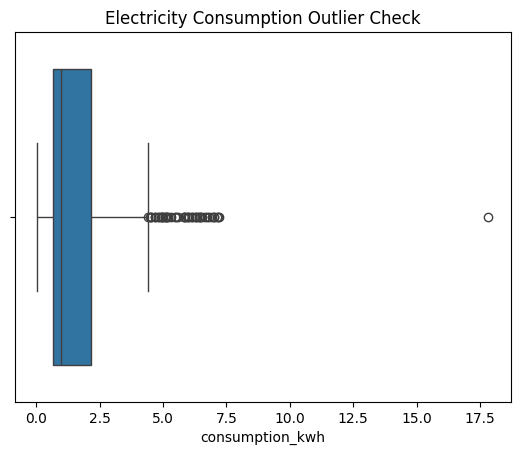

In [ ]:
sns.boxplot(data=meter, x="consumption_kwh")
plt.title("Electricity Consumption Outlier Check")
plt.show()

In [ ]:
df = meter.merge(
    customers.drop_duplicates("customer_id"),
    on="customer_id",
    how="left"
)

df = df.merge(weather, on="timestamp", how="left")
df = df.merge(calendar, on="timestamp", how="left")
df = df.merge(tariff, on="timestamp", how="left")

print("Combined shape:", df.shape)
print(df.head())

Combined shape: (988, 14)
            timestamp customer_id  consumption_kwh      segment     area  \
0 2025-01-01 00:00:00        C012            3.862   Industrial     West   
1 2025-01-01 01:00:00        C066            0.537  Residential     East   
2 2025-01-01 02:00:00        C097            0.163  Residential  Central   
3 2025-01-01 03:00:00        C087            1.213   Commercial    North   
4 2025-01-01 04:00:00        C028            0.878  Residential     East   

  connection_type  temperature_c  humidity_pct  rain_mm    weekday  holiday  \
0     Three-phase           22.0          77.1      0.0  Wednesday        0   
1     Three-phase           24.0          56.5      0.0  Wednesday        0   
2    Single-phase           18.1          65.6      0.0  Wednesday        0   
3    Single-phase           20.0          85.2      0.0  Wednesday        0   
4     Three-phase           21.8          77.9      0.0  Wednesday        0   

   season tariff_category  peak_period  
0

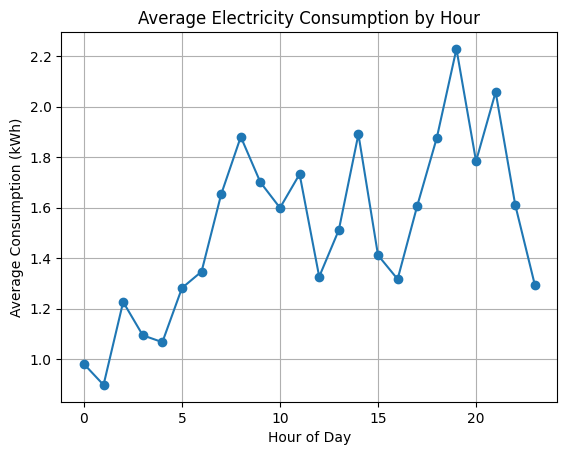

In [ ]:
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["hour"] = df["timestamp"].dt.hour

hourly = df.groupby("hour")["consumption_kwh"].mean()

hourly.plot(kind="line", marker="o")
plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Consumption (kWh)")
plt.grid(True)
plt.show()

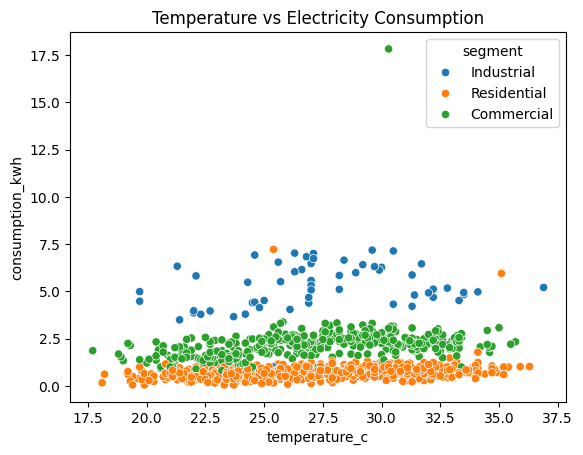

In [ ]:
sns.scatterplot(
    data=df,
    x="temperature_c",
    y="consumption_kwh",
    hue="segment"
)
plt.title("Temperature vs Electricity Consumption")
plt.show()

In [ ]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek
df["month"] = df["timestamp"].dt.month
df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

features = [
    "hour", "day_of_week", "month", "is_weekend",
    "temperature_c", "humidity_pct", "rain_mm",
    "holiday", "peak_period",
    "segment", "area", "connection_type",
    "weekday", "season", "tariff_category"
]

X = df[features]
y = df["consumption_kwh"]

numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(
    exclude="number"
).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore")
    ), categorical_cols)
])

model = make_pipeline(
    preprocessor,
    RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R² score:", round(r2, 3))

MAE: 0.302
RMSE: 1.159
R² score: 0.558
